# 22장 · 벡터 거리와 Chroma·FAISS 검색

분관 시간표와 분실물 안내에는 모두 ‘안내 데스크’가 등장합니다. FAISS가 반환한 위치를 청크 ID로 바꿔 토요일 운영 시간의 근거를 찾습니다. Chroma가 설치된 환경에서는 같은 벡터로 두 저장소의 결과를 비교합니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 faiss-cpu 1.15.1, numpy 2.5.4입니다. 이 교재에 저장된 출력은 Chroma 미설치 환경에서 얻었습니다. Chroma를 설치한 뒤 06~08번 셀을 실행해 두 청크를 저장하고, 다시 연 컬렉션에서 시간표를 찾아보세요.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 단어 벡터와 제곱 L2 거리

20장에서 읽고 21장에서 쪽 번호를 확인한 세 문장으로 시작합니다. 임베딩은 텍스트를 비교할 수 있는 숫자 배열로 표현합니다. 여기서는 단어가 있으면 1, 없으면 0을 쓰는 규칙을 직접 정합니다. 학습된 임베딩 모델이 동의어를 어떻게 표현하는지는 이 규칙으로 시험할 수 없습니다.

### 셀 01 · 대출·휴관·반납 세 좌표로 1쪽 표현하기

노트북 옆에 21장의 guide-records.json이 있으면 그 자료를 읽습니다. 파일을 따로 받지 않았을 때도 같은 세 문장으로 실행됩니다. 1쪽에서 어떤 단어가 첫 좌표를 1로 만드는지 보세요.

In [1]:
from pathlib import Path
import json

documents = [
    {"id": "library-1", "text": "도서 대출 기간은 14일입니다.", "source": "가상 도서관 이용 안내", "page": 1},
    {"id": "library-2", "text": "도서관은 월요일에 휴관합니다.", "source": "가상 도서관 이용 안내", "page": 2},
    {"id": "library-3", "text": "무인 반납함은 24시간 이용할 수 있습니다.", "source": "가상 도서관 이용 안내", "page": 3},
]
path = Path("guide-records.json")
if path.is_file():
    documents = json.loads(path.read_text(encoding="utf-8"))

terms = ("대출", "휴관", "반납")
def vector(text, vocabulary):
    return [float(word in text) for word in vocabulary]

baseline_vectors = [vector(doc["text"], terms) for doc in documents]
print(documents[0]["id"], baseline_vectors[0], documents[0]["text"])

library-1 [1.0, 0.0, 0.0] 도서 대출 기간은 14일입니다.


1쪽에는 ‘대출’만 있어 첫 좌표만 1입니다. 같은 세 문장과 좌표 순서를 23장에서도 씁니다. 분관 시간표를 검색할 때는 별도 단어 목록과 별도 인덱스를 만듭니다.

이 좌표는 세 단어 목록에서 ‘대출’을 첫 자리에 뒀기 때문에 [1.0, 0.0, 0.0]입니다. 질문 쪽에서만 단어 순서를 바꾸면 첫 좌표끼리 빼도 서로 다른 단어를 비교하게 됩니다. 새 단어 목록을 쓰고 싶다면 문서와 질문 양쪽의 벡터를 같은 순서로 다시 만들어야 합니다.


### 과제 02 · 휴관일 질문과 세 문장 사이의 거리 구하기

“휴관일은 언제인가요?”를 같은 단어 순서로 변환하세요. 각 문서와 같은 자리의 숫자끼리 뺀 뒤 제곱해서 더하세요. 어느 ID가 가장 가까운가요?

In [2]:
# 질문 벡터를 만들고 세 문서 각각의 제곱 L2 거리를 출력하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>query = vector(&quot;휴관일은 언제인가요?&quot;, terms)
for doc, stored in zip(documents, baseline_vectors):
    distance = sum((x - y) ** 2 for x, y in zip(query, stored))
    print(doc[&quot;id&quot;], distance)</code></pre>
<p>실행 결과</p><pre><code>library-1 2.0
library-2 0.0
library-3 2.0</code></pre>
<p>질문과 2쪽의 벡터는 [0, 1, 0]으로 같습니다. 거리는 0입니다. 1쪽과는 첫째·둘째 좌표가 각각 1만큼 달라서 거리가 2입니다. 이 수업의 두 저장소는 제곱 L2 거리를 사용하므로 작은 값부터 읽습니다.</p>
</details>

## 21장 인계 파일에서 분관 청크 열기

분관 이용 안내 2쪽에는 분실물을 맡기는 곳과 운영 시간표가 있습니다. 21장에서는 청크 크기 70자, 중첩 12자로 2쪽을 나눴습니다. 여기서는 두 청크만 검색 후보로 씁니다. start는 원문에서 세기 시작할 위치이고 end는 마지막 글자 바로 다음 위치입니다. 쪽 번호는 1부터, 글자 위치는 0부터 셉니다.

### 셀 03 · 저장해 둔 시간표와 분실물 청크 읽기

21장 과제에서 만든 chapter21-output/desk-hours.json을 노트북 옆 같은 경로에 두면 그 파일을 먼저 읽습니다. 함께 제공한 desk-hours.json은 같은 과제의 기준 결과입니다. 두 파일이 모두 없어도 노트북 안의 예시로 실습할 수 있습니다.

In [3]:
reference_page = '새솔도서관 분관 이용 안내\n2027년 3월 연습용 개정판\n\n무인 반납함\n중앙 출입구 오른쪽의 반납함은 매일 24시간 이용할 수 있습니다. 투입구가 가득 찼을 때에는 책을 바닥에 놓지 말고 다음 개관일에 대출대로 가져오세요.\n\n분실물 접수\n개인 소지품을 습득하면 2층 안내 데스크에 맡겨 주세요. 접수한 물건은 보름 동안 보관합니다. 찾으러 올 때에는 물건의 색상과 습득 장소를 직원에게 알려 주세요.\n\n운영 시간\n장소 | 평일 | 토요일\n안내 데스크 | 10:00~18:00 | 10:00~15:00\n무인 반납함 | 24시간 | 24시간'
pages = {2: reference_page}
guide = Path("branch-guide.txt")
if guide.is_file():
    pages = dict(enumerate(guide.read_text(encoding="utf-8").split("\f"), 1))

def reference_chunk(start, end, text):
    return {"id": f"branch-2:{start}", "document_id": "branch-2",
            "source": "branch-guide.txt", "page": 2, "start": start, "end": end,
            "chunk_size": 70, "chunk_overlap": 12, "text": text}

lost = reference_chunk(133, 199, '개인 소지품을 습득하면 2층 안내 데스크에 맡겨 주세요. 접수한 물건은 보름 동안 보관합니다. 찾으러 올 때에는 물건의')
desk = reference_chunk(225, 279, '운영 시간\n장소 | 평일 | 토요일\n안내 데스크 | 10:00~18:00 | 10:00~15:00')
for path in (Path("chapter21-output/desk-hours.json"), Path("desk-hours.json")):
    if path.is_file():
        desk = json.loads(path.read_text(encoding="utf-8"))
        break
chunks = [lost, desk]
print(desk["id"], desk["page"], desk["start"], desk["end"])
print(desk["text"])

branch-2:225 2 225 279
운영 시간
장소 | 평일 | 토요일
안내 데스크 | 10:00~18:00 | 10:00~15:00


기준 시간표는 branch-2:225이고 범위는 225 이상 279 미만입니다. 청크 안에 ‘장소 | 평일 | 토요일’이 남아 있어 마지막 열이 토요일이라는 것을 알 수 있습니다. 짝의 인계 파일을 읽었다면 실제로 출력된 ID와 범위를 기록하세요.

### 셀 04 · 출처와 글자 범위가 맞는지 검산하기

인계받은 JSON에 2쪽이라고 쓰여 있어도 위치가 틀릴 수 있습니다. 원문 범위를 검사하는 함수를 실행하고, 끝 위치를 한 글자 늘린 시간표 사본 한 건을 넣어 보세요.

In [4]:
def original_text(hit, pages):
    page = hit["page"]
    if (hit["source"] != "branch-guide.txt" or page not in pages
            or hit["document_id"] != f"branch-{page}"):
        raise ValueError("원문 파일, 문서 ID, 쪽 번호를 확인하세요.")
    start, end = hit["start"], hit["end"]
    if not 0 <= start < end <= len(pages[page]) or hit["id"] != f"branch-{page}:{start}":
        raise ValueError("청크 ID와 글자 범위를 확인하세요.")
    passage = pages[page][start:end]
    if passage != hit["text"]:
        raise ValueError("청크 본문이 원문 범위와 다릅니다.")
    return passage

for piece in chunks:
    original_text(piece, pages)
try:
    original_text({**desk, "end": desk["end"] + 1}, pages)
except ValueError as error:
    print(error)

청크 본문이 원문 범위와 다릅니다.


기준 자료에서는 끝 위치를 한 글자 늘리면 줄바꿈까지 가져와서 청크 본문과 다릅니다. 원래 청크가 쪽의 맨 끝까지 닿았다면 이번에는 글자 범위가 쪽을 벗어납니다. 다음 셀부터는 검사를 통과한 두 원본을 사용합니다.

### 셀 05 · 같은 표현을 쓰는 두 청크를 숫자로 구분하기

분관 실험의 세 좌표는 ‘안내 데스크’, ‘토요일’, ‘습득’입니다. 질문에 있는 단어와 두 본문에 있는 단어를 대조하세요. 어느 청크가 토요일 질문과 같은 좌표를 갖나요?

In [5]:
branch_terms = ("안내 데스크", "토요일", "습득")
question = "토요일 안내 데스크는 몇 시에 닫나요?"
query_vector = vector(question, branch_terms)
stored_vectors = [vector(piece["text"], branch_terms) for piece in chunks]
for piece, values in zip(chunks, stored_vectors):
    print(piece["id"], values)
print(question, query_vector)

branch-2:133 [1.0, 0.0, 1.0]
branch-2:225 [1.0, 1.0, 0.0]
토요일 안내 데스크는 몇 시에 닫나요? [1.0, 1.0, 0.0]


분실물 청크와 시간표 청크의 첫 좌표는 모두 1입니다. 시간표에는 ‘토요일’이, 분실물 청크에는 ‘습득’이 있어서 둘째·셋째 좌표가 갈립니다. 앞 절의 세 좌표와 길이가 같아도 단어의 뜻이 다릅니다. 두 실험의 벡터를 한 컬렉션에 섞으면 거리를 해석할 수 없습니다.

## Chroma 컬렉션에 쓰고 다시 열기

Chroma에는 벡터와 함께 청크 ID, 본문, 출처를 저장합니다. 컬렉션은 이 레코드들을 이름으로 다시 열 수 있는 묶음입니다. 노트북에서 chromadb를 찾지 못하면 새 셀에 %pip install "chromadb>=1.1,<2"를 실행하고 커널을 다시 시작하세요. 아래 셀들은 패키지 유무를 알립니다. FAISS 실습은 같은 두 청크에서 별도로 시작할 수 있습니다.

### 셀 06 · 실습 폴더의 컬렉션에 분실물 청크 한 건 쓰기

먼저 분실물 청크 하나를 저장합니다. 다음에 같은 폴더를 열 수 있도록 시간표 청크의 쪽 번호와 시작·끝 위치로 폴더 이름을 정합니다. get()으로 첫 번째 ID를 지정해 방금 쓴 본문을 확인하세요.

In [6]:
from importlib.util import find_spec

def metadata(piece):
    return {key: piece[key] for key in ("document_id", "source", "page", "start", "end")}

run_folder = Path("chapter22-output/chroma") / f"p{desk['page']}-{desk['start']}-{desk['end']}"
has_chroma = find_spec("chromadb") is not None
if has_chroma:
    import chromadb
    run_folder.mkdir(parents=True, exist_ok=True)
    client = chromadb.PersistentClient(path=str(run_folder))
    store = client.get_or_create_collection("branch_hours_v1", embedding_function=None,
                                            configuration={"hnsw": {"space": "l2"}})
    store.upsert(ids=[lost["id"]], embeddings=[stored_vectors[0]],
                 documents=[lost["text"]], metadatas=[metadata(lost)])
    print(store.get(ids=[lost["id"]])["ids"][0])
else:
    print("chromadb 미설치 · 저장 미실행")

chromadb 미설치 · 저장 미실행


upsert는 ID가 처음이면 레코드를 추가하고, 같은 ID가 있으면 내용을 갱신합니다. 같은 수업 폴더에서 셀을 다시 실행해도 같은 ID의 복사본이 쌓이지 않습니다. 기준 자료의 경로는 chapter22-output/chroma/p2-225-279입니다. 커널을 껐다 켠 뒤에도 이 폴더를 열 수 있습니다.

### 과제 07 · 시간표 청크와 벡터를 같은 ID로 저장하기

분실물과 같은 컬렉션에 시간표를 직접 넣으세요. ID와 본문, 쪽·범위는 desk에 있고 이 본문에서 계산한 벡터는 stored_vectors[1]입니다. upsert()에 네 값을 목록으로 넘기고 count()로 건수를 확인하세요. 같은 셀을 한 번 더 실행하면 건수가 바뀔까요?

In [7]:
# has_chroma가 참일 때 시간표의 ID·벡터·본문·메타데이터를 store.upsert에 넘기세요.
# 같은 셀을 두 번 실행하고 store.count()를 확인하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>if has_chroma:
    store.upsert(ids=[desk[&quot;id&quot;]], embeddings=[stored_vectors[1]],
                 documents=[desk[&quot;text&quot;]], metadatas=[metadata(desk)])
    print(store.count(), &quot;건 저장&quot;)
else:
    print(&quot;chromadb 미설치 · 시간표 등록 미실행&quot;)</code></pre>
<p>실행 결과</p><pre><code>chromadb 미설치 · 시간표 등록 미실행</code></pre>
<p>앞서 저장한 분실물 청크와 이번 시간표 청크는 ID가 다릅니다. 지정한 실습 컬렉션에는 두 건이 남고, 같은 ID와 내용으로 다시 쓰면 건수가 유지됩니다. 미설치 메시지가 나왔으면 셀의 upsert는 실행되지 않았습니다.</p>
</details>

### 셀 08 · 검색된 본문과 원문 쪽 대조하기

같은 폴더를 새 클라이언트로 열고 토요일 질문을 보냅니다. 과제 07을 비워뒀으면 먼저 시간표 한 건을 보충합니다. 반환값의 첫 대괄호는 질문 순서, 둘째는 그 질문 안에서 가까운 후보 순서입니다. 첫 후보를 골라 저장된 본문을 원문과 대조하세요.

In [8]:
chroma_hit = None
if has_chroma:
    reader = chromadb.PersistentClient(path=str(run_folder))
    reopened = reader.get_collection("branch_hours_v1", embedding_function=None)
    if not reopened.get(ids=[desk["id"]])["ids"]:
        reopened.upsert(ids=[desk["id"]], embeddings=[stored_vectors[1]],
                        documents=[desk["text"]], metadatas=[metadata(desk)])
    found = reopened.query(query_embeddings=[query_vector], n_results=1,
                           include=["documents", "metadatas", "distances"])
    chroma_hit = {**found["metadatas"][0][0], "id": found["ids"][0][0],
                  "text": found["documents"][0][0]}
    print(chroma_hit["id"], chroma_hit["source"], chroma_hit["page"])
    print(original_text(chroma_hit, pages))
else:
    print("chromadb 미설치 · 검색 결과의 원문 대조 미실행")

chromadb 미설치 · 검색 결과의 원문 대조 미실행


검색 결과의 document_id는 원문 쪽을 가리키고 id는 시간표 청크를 가리킵니다. 2쪽에서 직접 잘라 온 문장이 반환된 본문과 일치해야 참고할 수 있습니다. Chroma를 실행한 짝과 원문 파일 및 글자 범위를 교환해 같은 행이 나오는지 확인하세요.

#### 저장한 컬렉션에서 같은 문서 다시 찾기

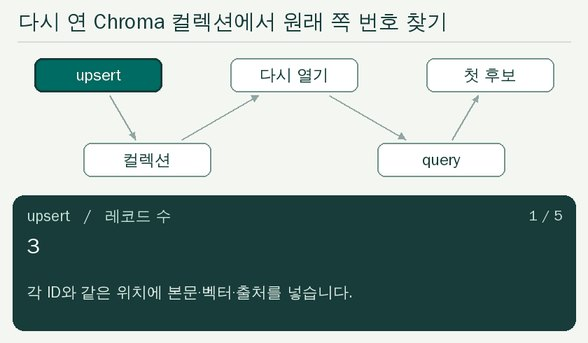

영상은 기준 문서 세 개를 저장한 예입니다. 대출 질의 [1, 0, 0]을 보내면 library-1과 1쪽을 돌려줍니다. 분관 시간표의 청크 ID와 쪽 번호는 이어지는 실습에서 확인하세요.

## FAISS 검색 위치를 청크 ID로 바꾸기

FAISS의 IndexFlatL2는 숫자 벡터를 보관하고 검색 결과로 행의 위치와 제곱 L2 거리를 돌려줍니다. 청크의 본문·ID·쪽은 우리가 저장 순서에 맞춰 따로 보관합니다. faiss 또는 numpy를 찾지 못하면 새 셀에서 %pip install faiss-cpu numpy를 실행하고 커널을 다시 시작하세요.

### 과제 09 · FAISS 인덱스에 같은 벡터를 넣고 검색하기

두 행을 float32 배열로 바꾸는 준비 코드는 제공합니다. 아래에 세 줄을 작성하세요. 배열의 열 수(벡터의 차원 수)를 IndexFlatL2에 넘겨 인덱스를 만들고, 두 행을 추가한 뒤 질문 벡터로 한 건을 검색합니다. 위치 1이 가리키는 ID와 거리를 출력하세요.

In [9]:
import faiss
import numpy as np

matrix = np.asarray(stored_vectors, dtype="float32")
query_array = np.asarray([query_vector], dtype="float32")
keys = [piece["id"] for piece in chunks]

# index_lab을 만들고 matrix를 추가한 뒤 query_array로 한 건을 검색하세요.
# 반환된 위치로 keys를 읽어 청크 ID와 거리를 출력하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>import faiss
import numpy as np

matrix = np.asarray(stored_vectors, dtype=&quot;float32&quot;)
query_array = np.asarray([query_vector], dtype=&quot;float32&quot;)
keys = [piece[&quot;id&quot;] for piece in chunks]
index_lab = faiss.IndexFlatL2(matrix.shape[1])
index_lab.add(matrix)
distances, positions = index_lab.search(query_array, 1)
position = int(positions[0, 0])
print(&quot;위치&quot;, position, &quot;ID&quot;, keys[position], &quot;거리&quot;, float(distances[0, 0]))</code></pre>
<p>실행 결과</p><pre><code>위치 1 ID branch-2:225 거리 0.0</code></pre>
<p>1은 두 번째로 넣은 행입니다. keys[1]을 읽으면 시간표의 ID가 나옵니다. FAISS가 문서 ID를 직접 돌려준다고 생각하고 1을 원문 쪽 번호로 사용하면 2쪽 시간표를 놓칩니다.</p>
</details>

### 과제 10 · 순서가 뒤집힌 ID 목록으로 오답 재현하고 고치기

동료가 ID 목록만 반대 순서로 저장했습니다. 같은 위치로 어느 본문을 꺼내는지 출력한 뒤, 벡터를 넣었던 순서에서 ID를 다시 구하세요. 고친 ID로 원문을 잘라 ‘안내 데스크 |’로 시작하는 행을 확인하세요. 앞 과제를 비워뒀으면 제공 코드가 인덱스를 준비합니다.

In [10]:
# 과제 09에 코드를 작성했다면 그 인덱스를 그대로 사용합니다.
if "index_lab" not in globals():
    index_lab = faiss.IndexFlatL2(matrix.shape[1])
    index_lab.add(matrix)
distances, positions = index_lab.search(query_array, 1)
position = int(positions[0, 0])

# keys를 뒤집은 목록과 원래 keys에 position을 각각 적용하세요.
# 바른 ID로 원문을 복원하고 시간표에서 안내 데스크 행을 출력하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code># 과제 09에 코드를 작성했다면 그 인덱스를 그대로 사용합니다.
if &quot;index_lab&quot; not in globals():
    index_lab = faiss.IndexFlatL2(matrix.shape[1])
    index_lab.add(matrix)
distances, positions = index_lab.search(query_array, 1)
position = int(positions[0, 0])

by_id = {piece[&quot;id&quot;]: piece for piece in chunks}
wrong_id = list(reversed(keys))[position]
print(&quot;잘못 연결한 ID&quot;, wrong_id)
print(by_id[wrong_id][&quot;text&quot;])
right_id = keys[position]
passage = original_text(by_id[right_id], pages)
print(&quot;복원한 ID&quot;, right_id)
print(next(line for line in passage.splitlines() if line.startswith(&quot;안내 데스크 |&quot;)))</code></pre>
<p>실행 결과</p><pre><code>잘못 연결한 ID branch-2:133
개인 소지품을 습득하면 2층 안내 데스크에 맡겨 주세요. 접수한 물건은 보름 동안 보관합니다. 찾으러 올 때에는 물건의
복원한 ID branch-2:225
안내 데스크 | 10:00~18:00 | 10:00~15:00</code></pre>
<p>검색 위치와 거리는 그대로인데 ID 목록만 뒤집으면 분실물 안내를 꺼냅니다. ID와 벡터의 행 순서를 함께 보관해야 하는 이유입니다. 시간표의 마지막 열을 보면 토요일에는 15시에 닫습니다.</p>
</details>

#### FAISS 위치 번호와 문서 ID

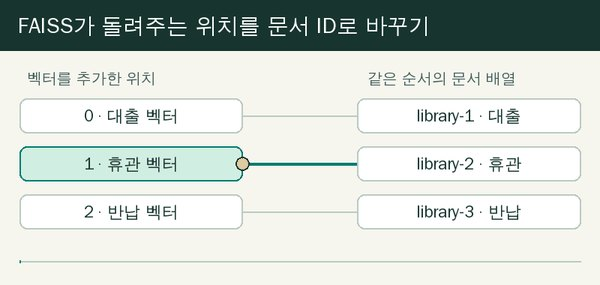

영상의 대출 문서는 입력 위치 0에 있어 library-1을 가리킵니다. 분관의 두 청크로 만든 인덱스에서는 같은 위치 0이 어느 청크를 가리키는지 노트북의 입력 순서와 대조하세요.

## 질문을 바꿔 검색 근거 검산하기

같은 인덱스에 다른 질문을 보냅니다. 질문이 바뀌면 벡터와 검색 위치가 어떻게 달라지는지 확인하고, 단어 목록으로 표현할 수 없는 질문에는 어떤 답을 건네야 할지 판단하세요.

### 과제 11 · 분실물 문의의 1위를 양쪽에서 검산하기

“안내 데스크에 습득한 물건을 맡기나요?”로 질의 벡터를 새로 만드세요. FAISS가 찾은 위치를 ID로 바꾸고 원문을 대조하세요. Chroma를 실행했다면 같은 벡터로 그 컬렉션까지 검색하고 두 ID가 일치하는지 확인하세요.

In [11]:
# 동일한 새 질의 벡터로 두 저장소를 조회하고 가장 가까운 청크 ID를 대조하세요.
# 원문의 어느 문장이 물건을 맡기는 곳을 알려 주나요?

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>next_query = vector(&quot;안내 데스크에 습득한 물건을 맡기나요?&quot;, branch_terms)
d, p = index_lab.search(np.asarray([next_query], dtype=&quot;float32&quot;), 1)
faiss_piece = chunks[int(p[0, 0])]
print(faiss_piece[&quot;id&quot;], float(d[0, 0]))
print(original_text(faiss_piece, pages).split(&quot;.&quot;)[0] + &quot;.&quot;)
if chroma_hit is not None:
    other = reopened.query(query_embeddings=[next_query], n_results=1, include=[&quot;distances&quot;])
    print(&quot;같은 1위&quot;, other[&quot;ids&quot;][0][0] == faiss_piece[&quot;id&quot;])
else:
    print(&quot;Chroma 비교 미실행&quot;)</code></pre>
<p>실행 결과</p><pre><code>branch-2:133 0.0
개인 소지품을 습득하면 2층 안내 데스크에 맡겨 주세요.
Chroma 비교 미실행</code></pre>
<p>기준 자료에서는 분실물 청크와 새 질문의 벡터가 같아 FAISS 위치 0이 나옵니다. 원문은 습득한 물건을 2층 안내 데스크에 맡기라고 안내합니다. Chroma를 실행한 경우에는 두 ID가 같은지까지 확인할 수 있습니다.</p>
</details>

### 셀 12 · 주차 요금 질문에서 같은 거리가 나오는 이유

이번에는 두 후보의 거리를 모두 출력합니다. 첫 번째로 돌아온 결과만 보고 주차 요금을 말할 수 있을까요? 같은 거리로 나온 후보 사이의 순서는 해석하지 않습니다.

In [12]:
unknown = vector("주차 요금은 얼마인가요?", branch_terms)
d, p = index_lab.search(np.asarray([unknown], dtype="float32"), 2)
print("질문 벡터", unknown)
print("두 후보의 거리", sorted(float(value) for value in d[0]))
if not any(unknown):
    print("질문을 표현하는 단어가 없습니다. 주차 안내를 확인하세요.")

질문 벡터 [0.0, 0.0, 0.0]
두 후보의 거리 [2.0, 2.0]
질문을 표현하는 단어가 없습니다. 주차 안내를 확인하세요.


질문 벡터가 [0, 0, 0]이고 두 청크 모두 1인 좌표가 두 개라서 거리가 2로 같습니다. 검색기는 두 후보를 반환했지만 어느 문장에도 주차 요금이 없습니다. 이 규칙의 영벡터는 질문에 해당하는 단어를 찾지 못했다는 신호입니다. 실제 임베딩 모델의 답변 가능 여부에는 이 판단을 그대로 적용할 수 없습니다.

## 돌아보기

짝이 운영 시간과 분실물 중에서 질문 하나를 고르면 질문 벡터, 1위 ID, 원문 쪽과 글자 범위를 알려 주세요. 짝은 원문에서 답이 될 문장을 찾아 확인합니다. 이어서 두 청크에 답이 없는 질문도 하나씩 바꿔 보세요. 23장 검색 함수의 기준 자료는 library-1·2·3과 대출·휴관·반납 세 좌표입니다.